<a href="https://colab.research.google.com/github/matheeshagit/Covertype_Deep_Learning_Solution/blob/main/Covertype.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
covertype = fetch_ucirepo(id=31)

# data (as pandas dataframes)
X = covertype.data.features
y = covertype.data.targets

In [ ]:
X.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,0
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,0
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,0
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,0
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 54 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Elevation                           581012 non-null  int64
 1   Aspect                              581012 non-null  int64
 2   Slope                               581012 non-null  int64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  int64
 4   Vertical_Distance_To_Hydrology      581012 non-null  int64
 5   Horizontal_Distance_To_Roadways     581012 non-null  int64
 6   Hillshade_9am                       581012 non-null  int64
 7   Hillshade_Noon                      581012 non-null  int64
 8   Hillshade_3pm                       581012 non-null  int64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  int64
 10  Wilderness_Area1                    581012 non-null  int64
 11  Soil_Type1                          581012 non-null 

In [ ]:
X.shape

(581012, 54)

In [ ]:
y.value_counts()

,count
Cover_Type,
2,283301
1,211840
3,35754
7,20510
6,17367
5,9493
4,2747


In [ ]:
X.duplicated().sum()

np.int64(0)

In [ ]:
X.isnull().sum()

,0
Elevation,0
Aspect,0
Slope,0
Horizontal_Distance_To_Hydrology,0
Vertical_Distance_To_Hydrology,0
Horizontal_Distance_To_Roadways,0
Hillshade_9am,0
Hillshade_Noon,0
Hillshade_3pm,0
Horizontal_Distance_To_Fire_Points,0


## Preprocessing

In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [4]:
#Fix Target Classes
y_array = y.values.ravel() - 1

#Seperate continuous features from binary features
continuous_cols = X.columns[:10]
binary_cols = X.columns[10:]

In [5]:
#Train, validation, test split and Scale continuous features
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_array,
    test_size=0.30,
    random_state=42,
    stratify=y_array
)

scaler = StandardScaler()
X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_temp[continuous_cols] = scaler.transform(X_temp[continuous_cols])

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

In [6]:
print(f"Training set shape:   {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Test set shape:       {X_test.shape}")

Training set shape:   (406708, 54)
Validation set shape: (87152, 54)
Test set shape:       (87152, 54)


## Deep Learning Feedforward Network

In [26]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [29]:
input_shape = [54]

model = keras.Sequential([
    layers.Dense(units=256, activation='relu', input_shape=(X_train.shape[1],)),
    layers.BatchNormalization(),
    layers.Dense(units=128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(units=64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(units=7, activation='softmax'),
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [30]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=512,
    verbose=1
)

Epoch 1/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.7943 - loss: 0.5390 - val_accuracy: 0.8359 - val_loss: 0.3937
Epoch 2/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.8535 - loss: 0.3559 - val_accuracy: 0.8645 - val_loss: 0.3289
Epoch 3/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.8749 - loss: 0.3068 - val_accuracy: 0.8806 - val_loss: 0.2933
Epoch 4/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8864 - loss: 0.2783 - val_accuracy: 0.8919 - val_loss: 0.2676
Epoch 5/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.8952 - loss: 0.2574 - val_accuracy: 0.8938 - val_loss: 0.2597
Epoch 6/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9018 - loss: 0.2424 - val_accuracy: 0.8969 - val_loss: 0.2546
Epoch 7/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.9064 - loss: 0.2309 - val_accuracy: 0.9063 - val_loss: 0.2295
Epoch 8/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9106 - loss: 0.2215 - 

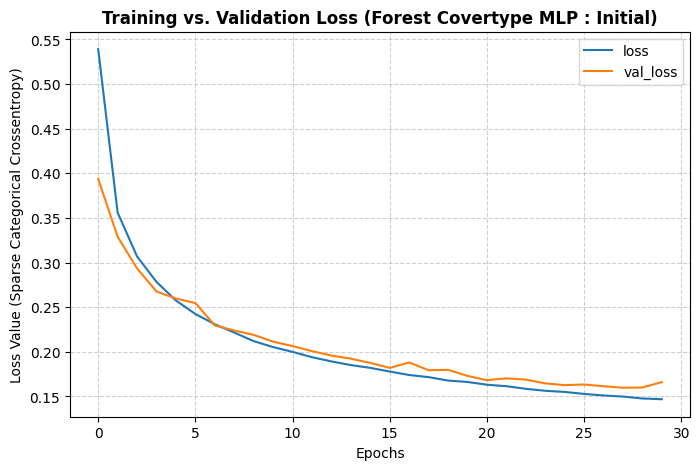

In [31]:
history_df = pd.DataFrame(history.history)
ax = history_df.loc[:, ['loss', 'val_loss']].plot(figsize=(8, 5))
ax.set_title(
    'Training vs. Validation Loss (Forest Covertype MLP : Initial)',
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Epochs', fontsize=10)
ax.set_ylabel('Loss Value (Sparse Categorical Crossentropy)', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.6)
plt.savefig(
    'loss_curve_initial.png', dpi=300, bbox_inches='tight'
)
plt.show()

### Use Dropout

In [32]:
model = keras.Sequential([
    layers.Dense(units=256, activation='relu', input_shape=(X_train.shape[1],)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(units=128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(units=64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(units=7, activation='softmax'),
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=512,
    verbose=1
)

Epoch 1/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.7341 - loss: 0.6826 - val_accuracy: 0.7975 - val_loss: 0.4841
Epoch 2/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 29s 36ms/step - accuracy: 0.7854 - loss: 0.5039 - val_accuracy: 0.8248 - val_loss: 0.4193
Epoch 3/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 21s 26ms/step - accuracy: 0.8046 - loss: 0.4595 - val_accuracy: 0.8455 - val_loss: 0.3779
Epoch 4/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.8175 - loss: 0.4315 - val_accuracy: 0.8507 - val_loss: 0.3569
Epoch 5/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8266 - loss: 0.4122 - val_accuracy: 0.8620 - val_loss: 0.3378
Epoch 6/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.8329 - loss: 0.3970 - val_accuracy: 0.8659 - val_loss: 0.3266
Epoch 7/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.8390 - loss: 0.3852 - val_accuracy: 0.8744 - val_loss: 0.3091
Epoch 8/30
795/795 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.8423 - loss: 0.3768 - 

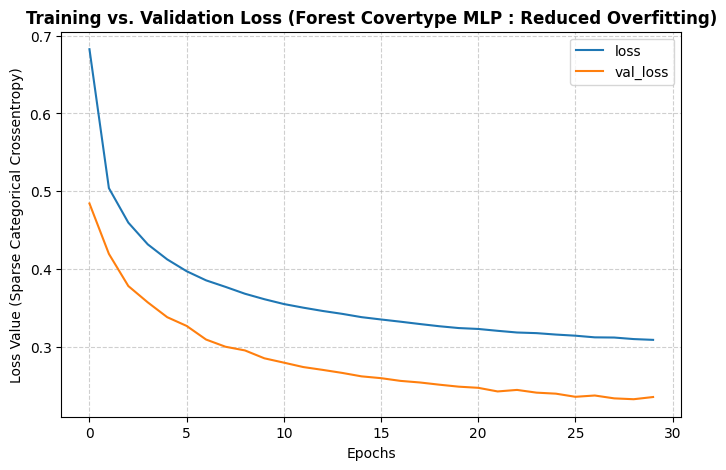

In [35]:
history_df = pd.DataFrame(history.history)
ax = history_df.loc[:, ['loss', 'val_loss']].plot(figsize=(8, 5))
ax.set_title(
    'Training vs. Validation Loss (Forest Covertype MLP : Reduced Overfitting)',
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Epochs', fontsize=10)
ax.set_ylabel('Loss Value (Sparse Categorical Crossentropy)', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.6)
plt.savefig(
    'loss_curve_v2.png', dpi=300, bbox_inches='tight'
)
plt.show()

## Let's deep the network and add early stopping


In [8]:
model = keras.Sequential([
    layers.Dense(units=512, activation='relu', input_shape=(X_train.shape[1],)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(units=256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(units=128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(units=64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(units=7, activation='softmax'),
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [10]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, verbose=1, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss',factor=0.1, patience=5, verbose=1)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=512,
    callbacks=callbacks,
    verbose=0
)

Restoring model weights from the end of the best epoch: 50.


Minimum validation loss: 0.16978885233402252


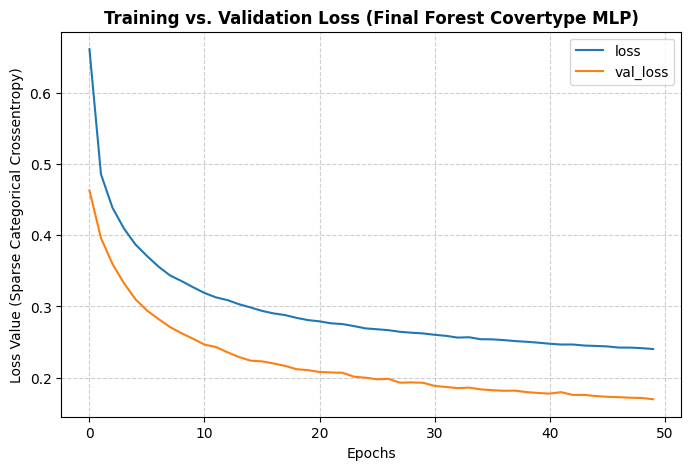

In [25]:
history_df = pd.DataFrame(history.history)
print("Minimum validation loss: {}".format(history_df['val_loss'].min()))

ax = history_df.loc[:, ['loss', 'val_loss']].plot(figsize=(8, 5))
ax.set_title(
    'Training vs. Validation Loss (Final Forest Covertype MLP)',
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Epochs', fontsize=10)
ax.set_ylabel('Loss Value (Sparse Categorical Crossentropy)', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.6)
plt.savefig(
    'loss_curve_final.png', dpi=300, bbox_inches='tight'
)
plt.show()

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

In [13]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_accuracy * 100:.2f}%')

Test Loss: 0.1707
Test Accuracy: 93.19%


In [14]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test, y_pred))

2724/2724 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step
              precision    recall  f1-score   support

           0       0.94      0.92      0.93     31776
           1       0.94      0.95      0.94     42496
           2       0.93      0.94      0.93      5363
           3       0.87      0.82      0.85       412
           4       0.82      0.80      0.81      1424
           5       0.88      0.89      0.88      2605
           6       0.92      0.95      0.93      3076

    accuracy                           0.93     87152
   macro avg       0.90      0.89      0.90     87152
weighted avg       0.93      0.93      0.93     87152



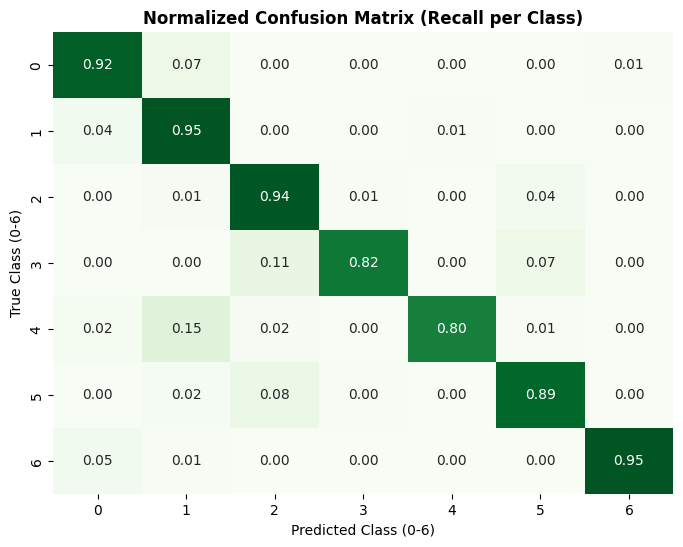

In [27]:
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred, normalize='true')
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Greens', cbar=False, vmin=0, vmax=1)
plt.title(
    'Normalized Confusion Matrix (Recall per Class)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Predicted Class (0-6)')
plt.ylabel('True Class (0-6)')
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()